# Ball-missing and missing-player analysis

Ball coordinates can disappear without the ball actually leaving the phase of play. This notebook treats the disappearance as an observation problem, not as permission to invent an exact ball path.

## Robust interpretation

- Look backward to the last controlled player/team evidence and forward to the first reliable reappearance or control evidence.
- Preserve the prior team during an unresolved gap when the trajectory, receiver path, and post-gap team agree.
- Keep the interval contested when both teams converge, the ball decelerates near pressure, or the next touch is not controlled.
- Treat low motion, out-of-play geometry, restart context, and second-half pre-kickoff as dead-ball evidence—not as fixed-duration labels.
- A missing player near the apparent ball path is handled as uncertainty in the observation, not as a new track identity.

The feature bank exposes these as confidence signals. The decoder decides how much each signal changes H/A/D confidence.

George's alternate-camera observations add a source-aware view of the gap: `source`, `sigma_m`, `gap_s`, and bounded `p_video`/`p_carrier`/`p_dead`. The safe path uses them to explain missingness and uncertainty, never to copy an owning team.

## George/Kalman path evidence

The missing-ball path is selected conservatively: `GEORGE_DIRECT` → `GEORGE_FLIGHT` → a short, two-sided, low-uncertainty `KALMAN` estimate. Visible tactical coordinates remain primary. George's reconstructed flight and Kalman are alternative explanations of the same hidden interval, not independent probabilities to add together.

The selected path is used to test whether nearby H/A players could plausibly receive the ball: compare forward/backward player trajectories with the path, estimate arrival and pressure, then require contact or a sharp motion change plus persistent post-touch control before supporting a switch. If both teams remain plausible, emit uncertainty/`CONTESTED` or retain `NO_SWITCH`; Kalman never assigns possession by itself.

The signal-panel kick/contact candidate is a motion-change feature at the visible gap edge. In this notebook it is observed tactical evidence unless the legend explicitly says George-supported; it is not a filled ball track or a possession label.

## Observable cases

| Observation pattern | Evidence signal | Conservative interpretation |
|---|---|---|
| Nearby endpoint displacement with coherent direction | `gap_nearby_teleport_candidate` | ball may have been briefly unobserved; do not change team alone |
| Same area and all-player slowdown | `gap_same_area_low_motion_dead_candidate` | dead-ball candidate |
| Path ends at a player and the same team controls after reappearance | `gap_same_team_reappearance_candidate` | retain prior team through the gap |
| Prior team before the gap, opposing team controls after it | `gap_opponent_reappearance_switch_candidate` | provisional switch; require post-gap persistence |
| Receiver accelerates while the ball is missing | `gap_receiver_acceleration_candidate` | likely continuation to that receiver, not an exact path estimate |
| Ball slows in open space, then moves again without a nearby receiver | `gap_pass_to_space_candidate` / `gap_opponent_near_miss_candidate` | keep prior team or contested until control appears |
| Out-of-play or restart context | `gap_out_of_play_dead_candidate`, restart signals | protect D until live control is visible |

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'possession_lab').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from possession_lab.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession_lab.calculations.features import build_engineered_features
from possession_lab.pipeline import detect_scenario_evidence
from possession_lab.calculations.plotting import plot_evidence_window, plot_transition_signals_window, select_ball_gap_event_window
from starter.load_atd import load as load_starter_atd
from starter.utils import animate_frames
from games import asset_paths

model = ClosestTeamRuleModel()
features = detect_scenario_evidence(build_engineered_features(model=model))
missing = features['ball_x'].isna() | features['ball_y'].isna()
starts = np.flatnonzero(missing.to_numpy() & ~np.r_[False, missing.to_numpy()[:-1]])
ends = np.flatnonzero(missing.to_numpy() & ~np.r_[missing.to_numpy()[1:], False])
episodes = []
signal_columns = [column for column in [
    'gap_nearby_teleport_candidate', 'gap_same_area_low_motion_dead_candidate',
    'gap_same_team_reappearance_candidate', 'gap_opponent_reappearance_switch_candidate',
    'gap_receiver_acceleration_candidate', 'gap_pass_to_space_candidate',
    'gap_opponent_near_miss_candidate', 'gap_out_of_play_dead_candidate',
    'restart_low_motion_cluster_candidate', 'restart_live_control_candidate',
    'second_half_pre_kickoff_dead_candidate', 'gap_same_team_confidence',
    'gap_switch_confidence', 'gap_deadball_confidence', 'gap_pass_to_space_confidence',
] if column in features.columns]
for start, end in zip(starts, ends):
    if start == 0 or end + 1 >= len(features):
        continue
    row = features.iloc[start]
    record = {'start_frame': int(row['frame']), 'end_frame': int(features.iloc[end]['frame']),
              'duration_s': (end - start + 1) / 25.0}
    for column in signal_columns:
        value = features.iloc[start][column]
        record[column] = bool(value) if isinstance(value, (bool, np.bool_)) else value
    episodes.append(record)
episodes = pd.DataFrame(episodes).sort_values(['duration_s', 'start_frame'], ascending=[False, True])
display(episodes.head(25))
print(f'internal missing-ball episodes: {len(episodes)}')

# George's CSV is inspected by provenance, not treated as a complete truth track.
george_path = ROOT / 'data' / 'ball' / 'BAR-ATH_ball.csv'
if george_path.exists():
    george_table = pd.read_csv(george_path)
    source_summary = (george_table.groupby('source', dropna=False)
                     .agg(frames=('frame', 'size'), median_sigma_m=('sigma_m', 'median'),
                          median_p_video=('p_video', 'median'), median_p_carrier=('p_carrier', 'median'),
                          median_p_dead=('p_dead', 'median'))
                     .sort_values('frames', ascending=False))
    display(source_summary)
    print('George CSV rows:', len(george_table), '| source classes:', source_summary.index.tolist())
else:
    print('George CSV not present; the notebook still documents the required source contract.')

,start_frame,end_frame,duration_s
148,157546,163082,221.48
1,5108,10642,221.40
41,58081,61546,138.64
68,86615,88351,69.48
56,73997,75531,61.40
55,72560,73950,55.64
30,46678,48030,54.12
52,70196,71519,52.96
165,175715,176992,51.12
158,168918,170177,50.40


internal missing-ball episodes: 184
George CSV not present; the notebook still documents the required source contract.


## Case frame evidence and full-range animations

Each selected gap now has three complementary views. The pitch panel is restricted to the last observed ball frame through the next observed ball frame, draws the missing-ball displacement as an orange bridge, and summarizes nearby player movement as an occupancy heatmap; individual paths can be enabled for a detailed audit. The evidence timeline and a compact signal panel show the corresponding ball speed, recent ball distance, acceleration/contact impulse, and missingness. The animation still plays the complete selected frame range with all tracked players. Examples are restricted to windows whose public ground-truth strip is fully graded (`H`, `A`, or `D`); windows containing ungraded `X` frames are skipped. In the bundled public reference this is one 300-second graded interval, frames 11185–18684; the match-clock display is a clip offset, not a second grading window. The animation is inspection evidence, not a hidden-label source.

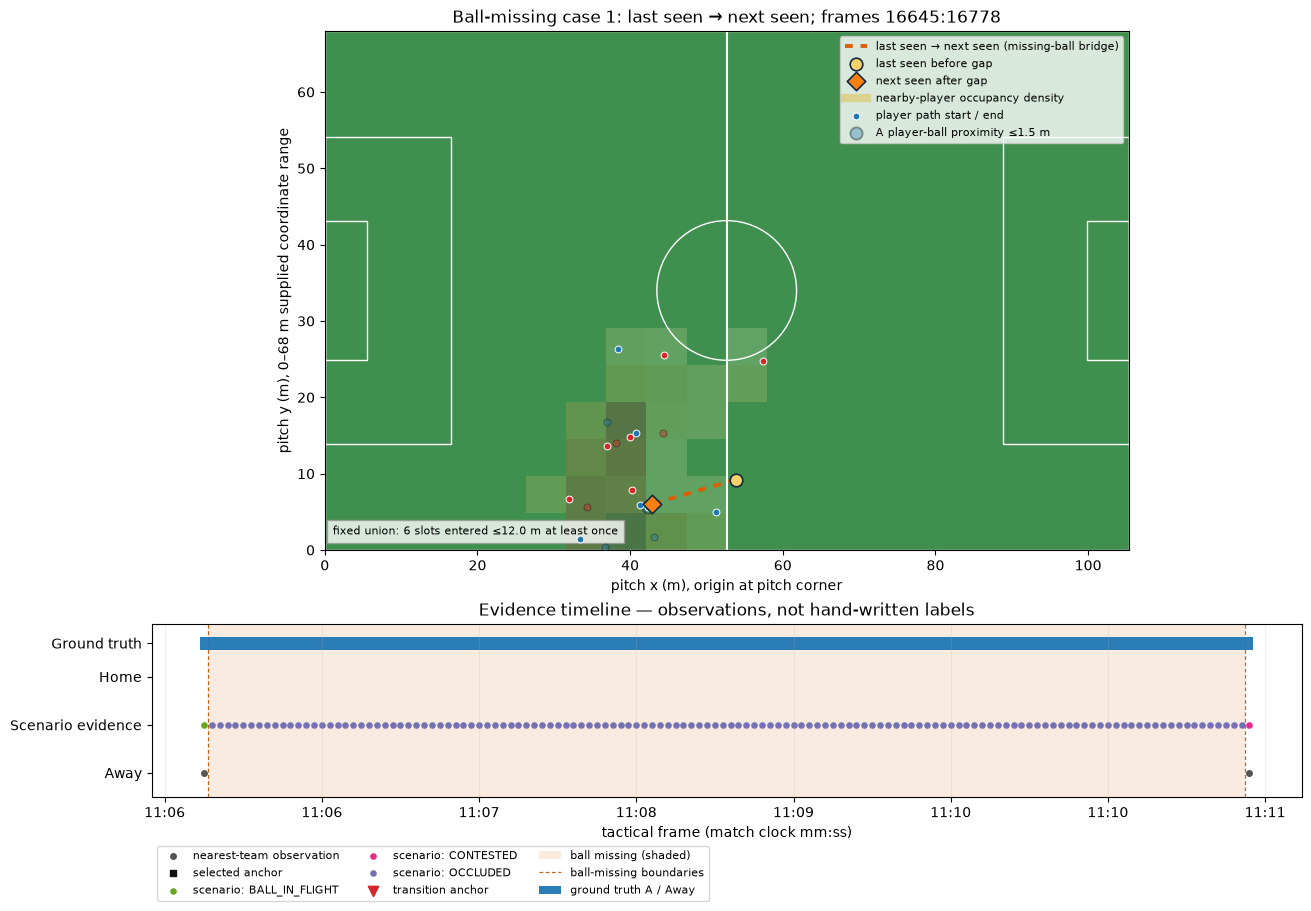

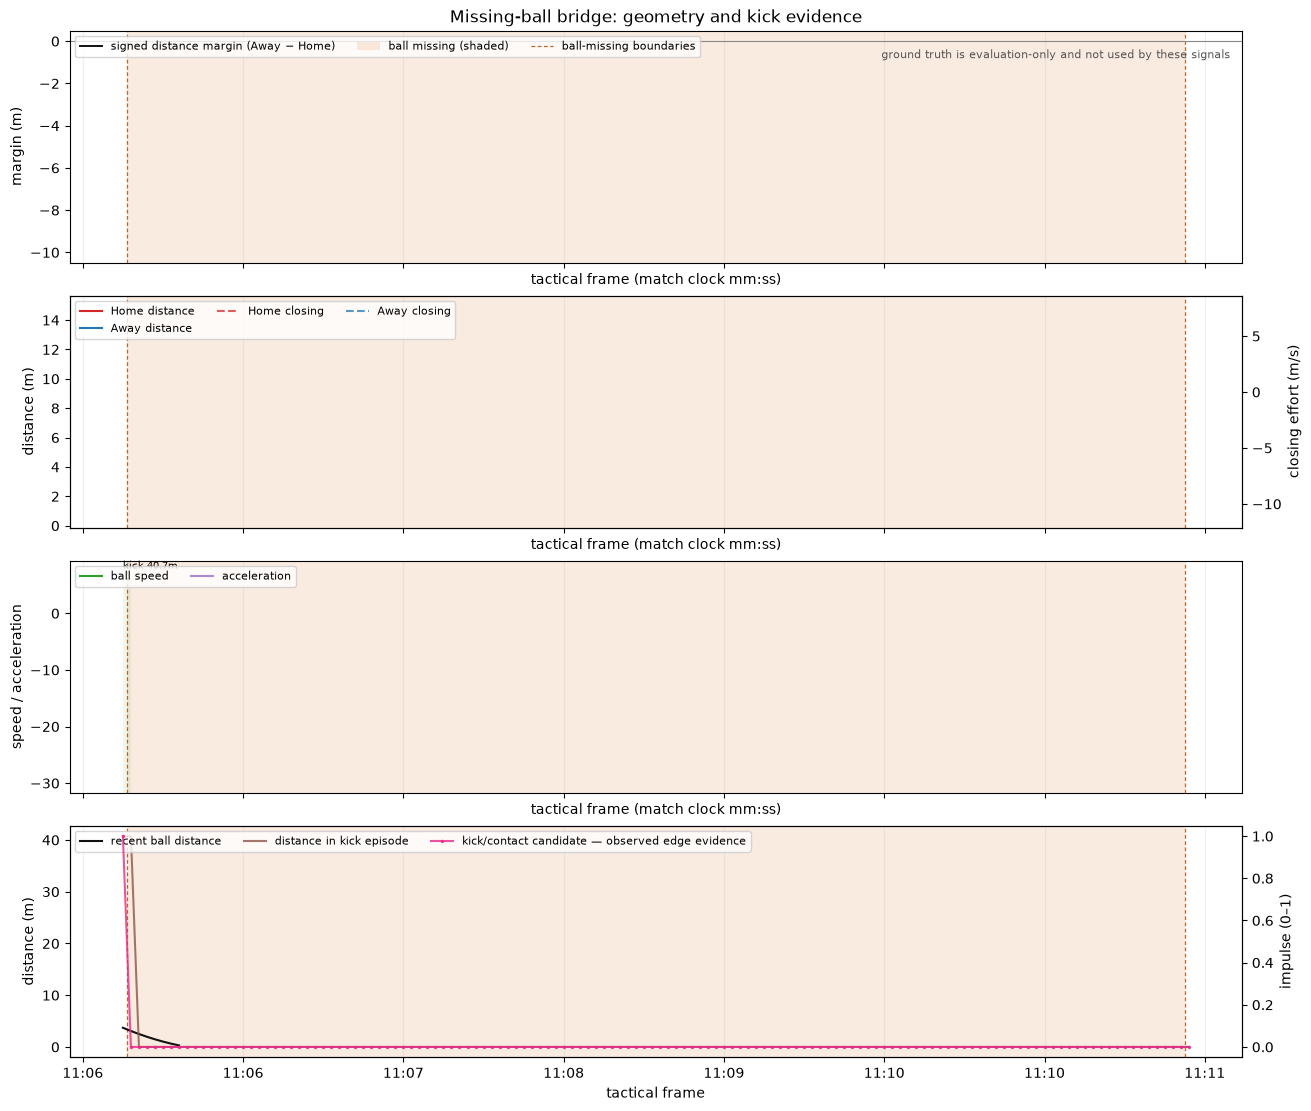

**Full-range playback:** frames 16571–16852; graded H/A/D window; the ball is allowed to disappear honestly.

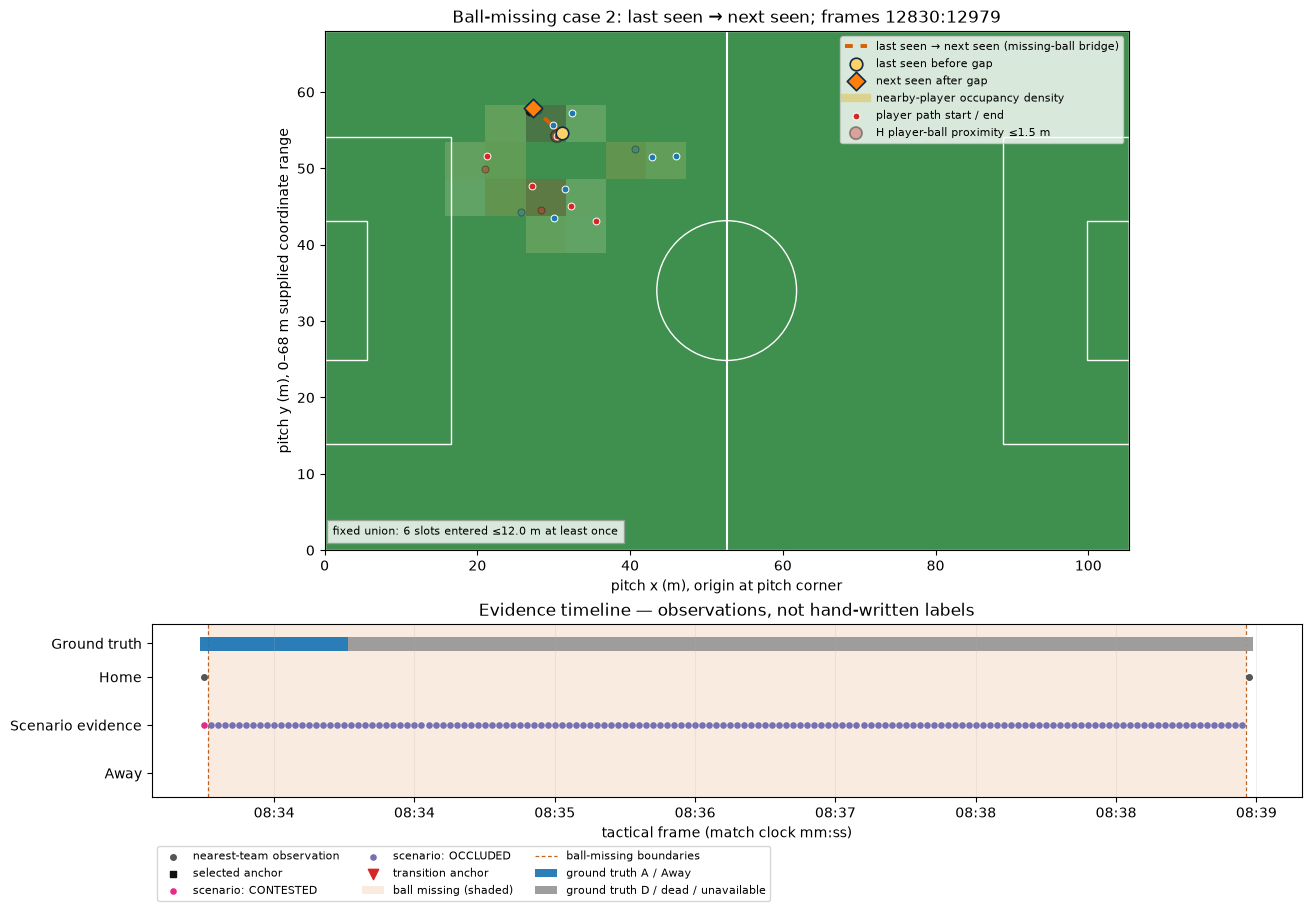

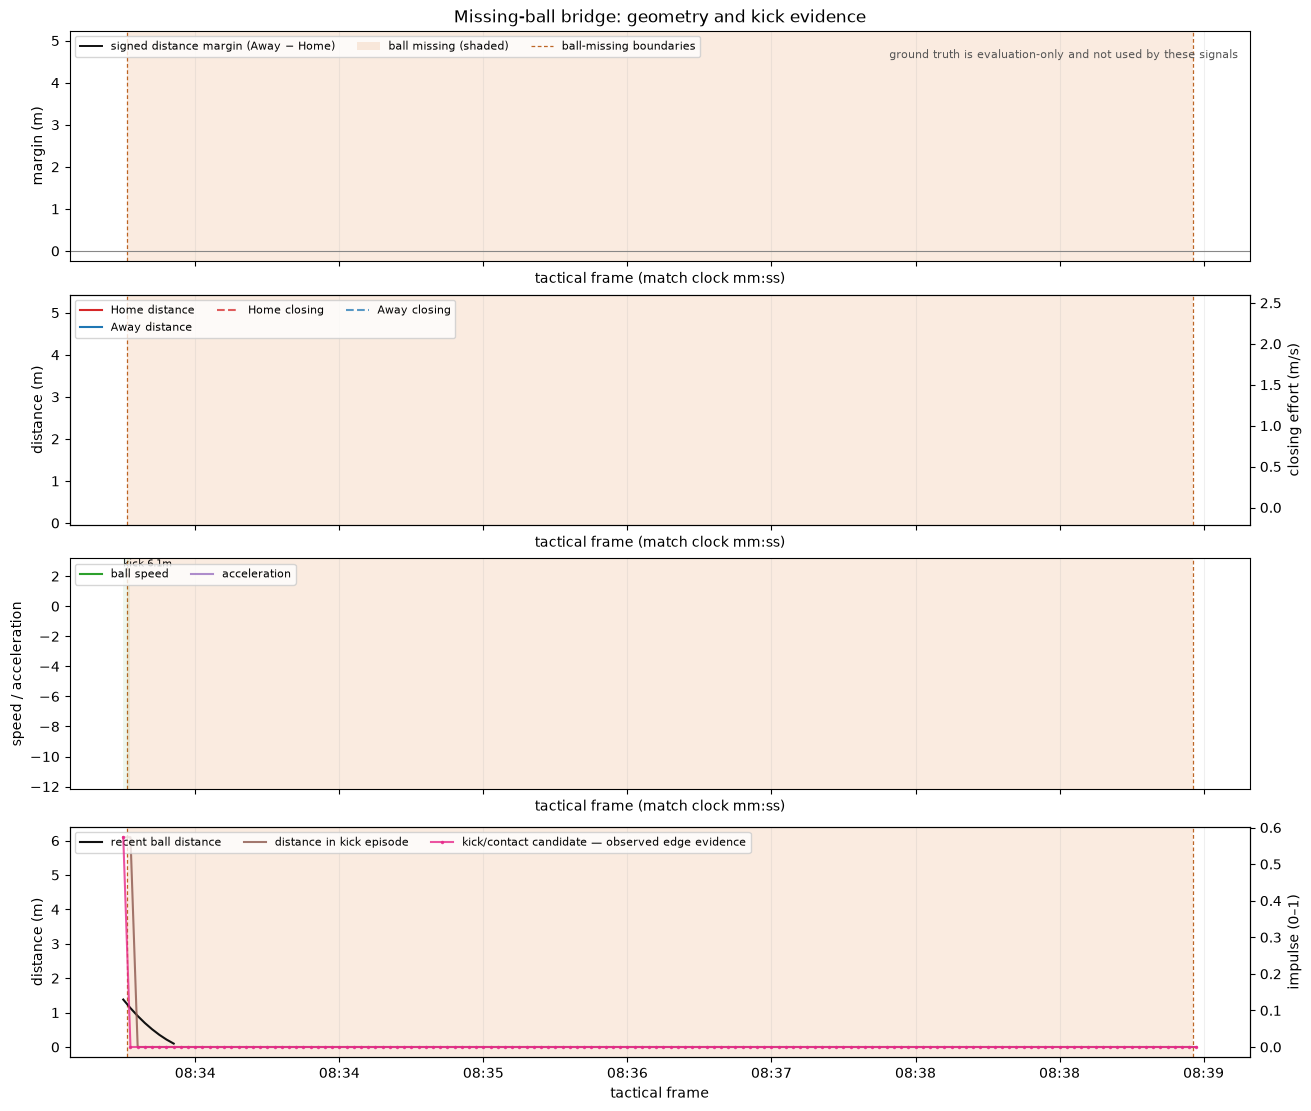

**Full-range playback:** frames 12756–13053; graded H/A/D window; the ball is allowed to disappear honestly.

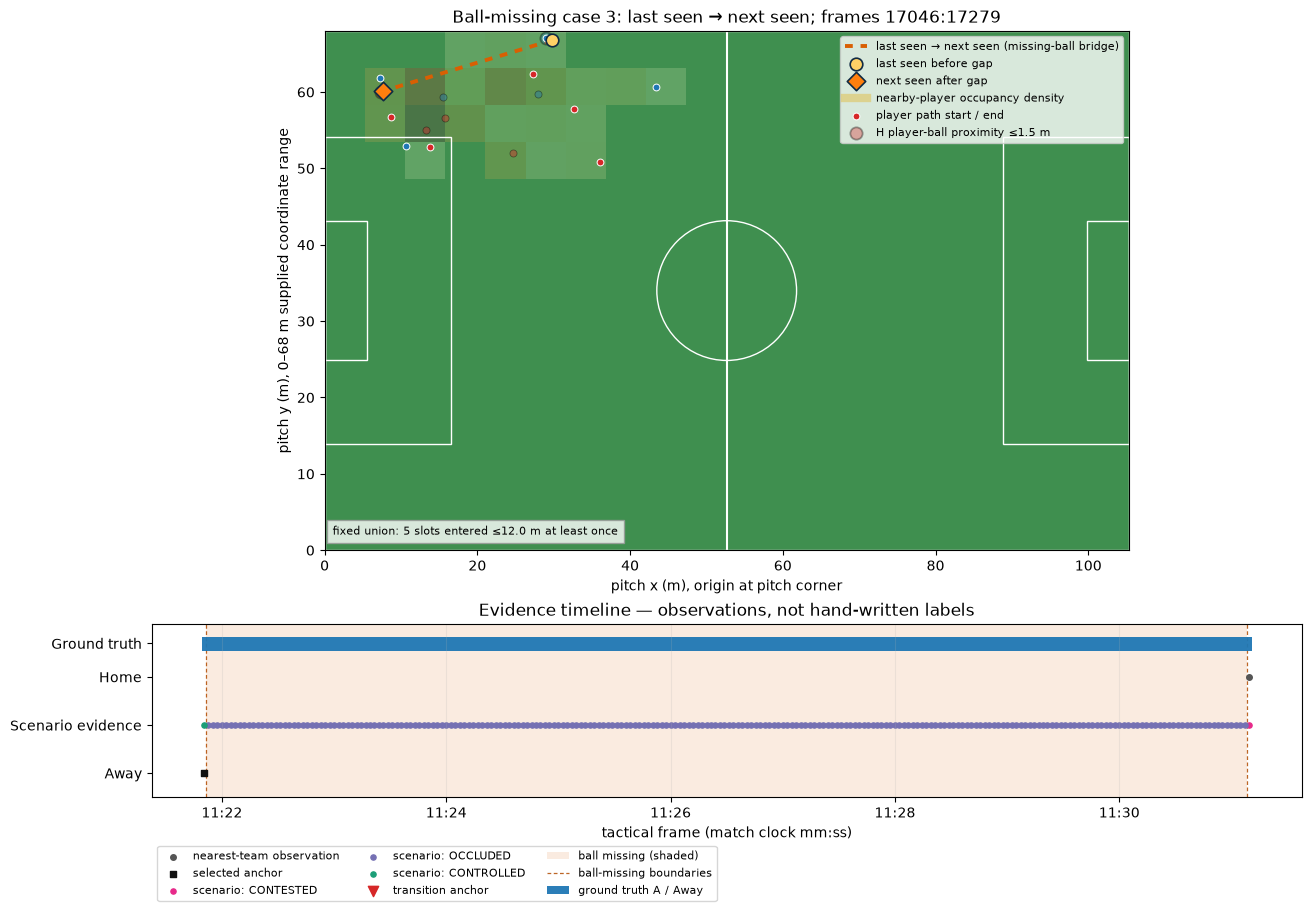

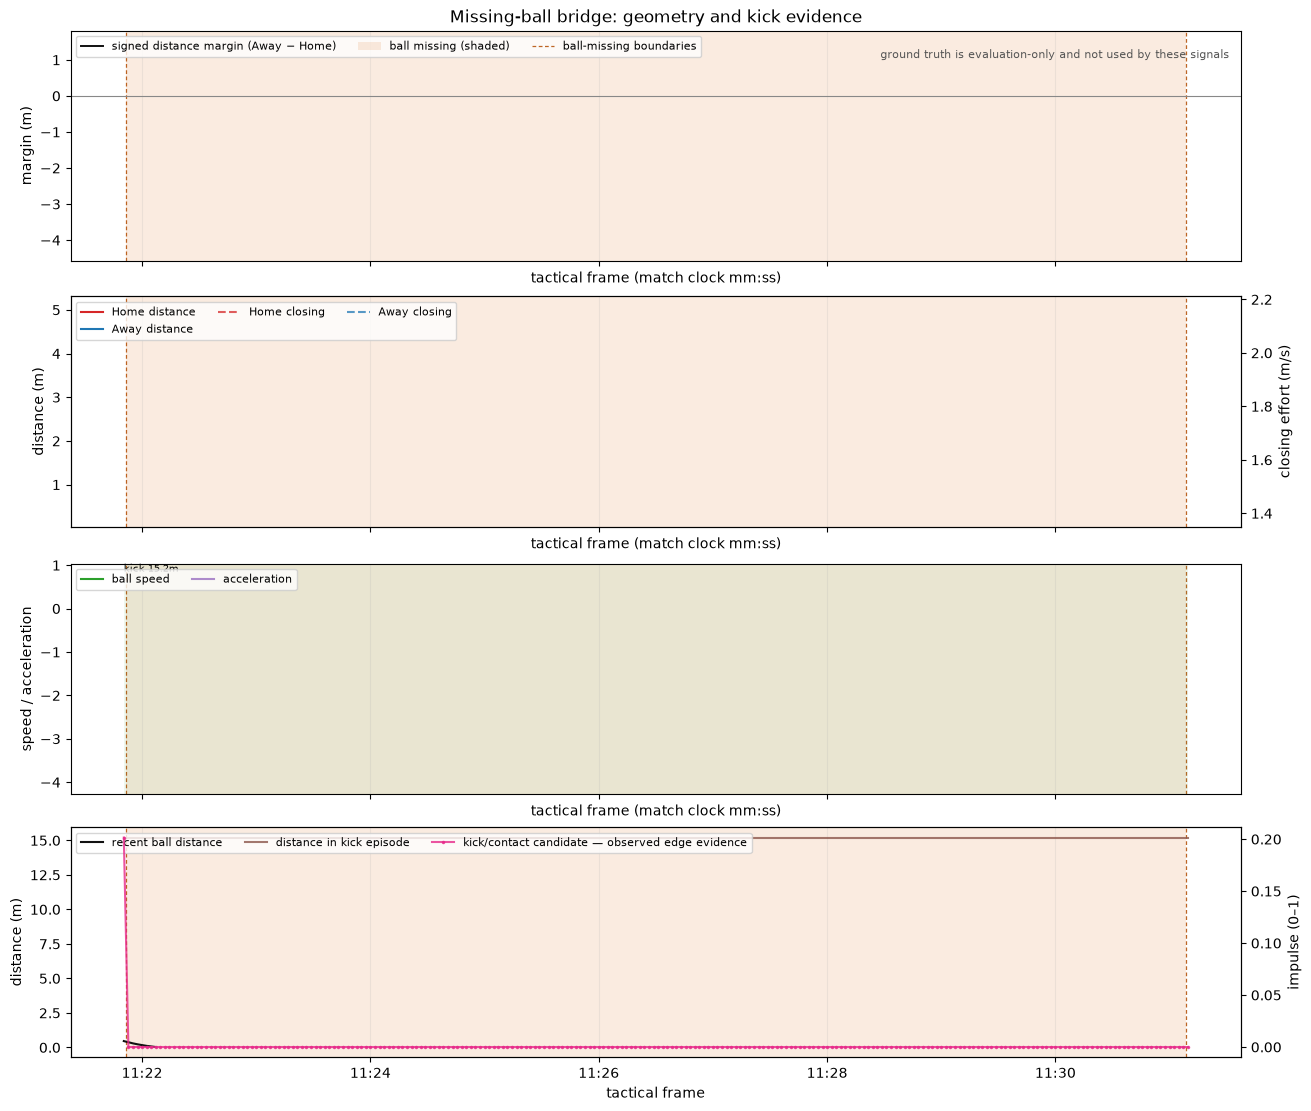

**Full-range playback:** frames 16972–17353; graded H/A/D window; the ball is allowed to disappear honestly.

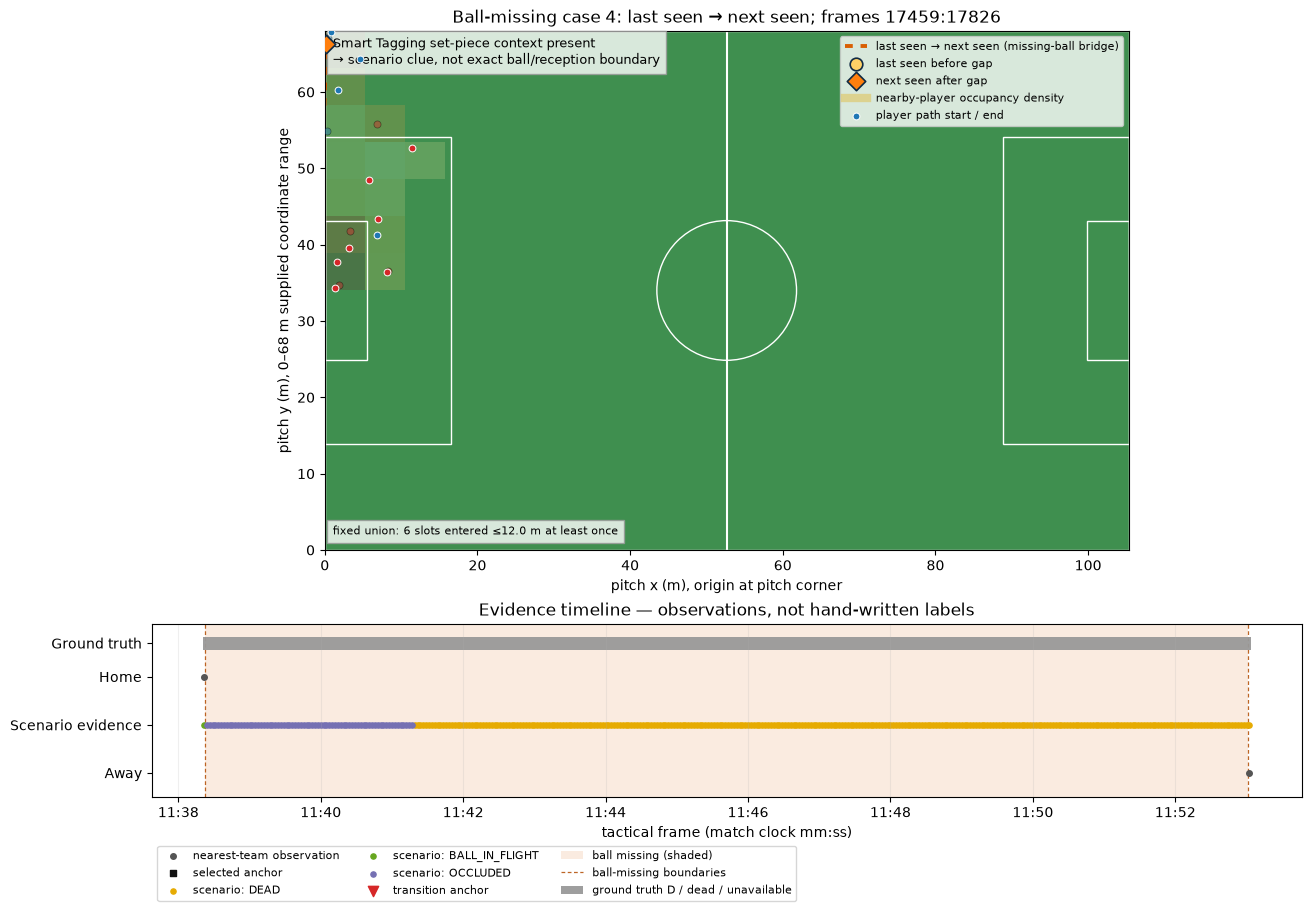

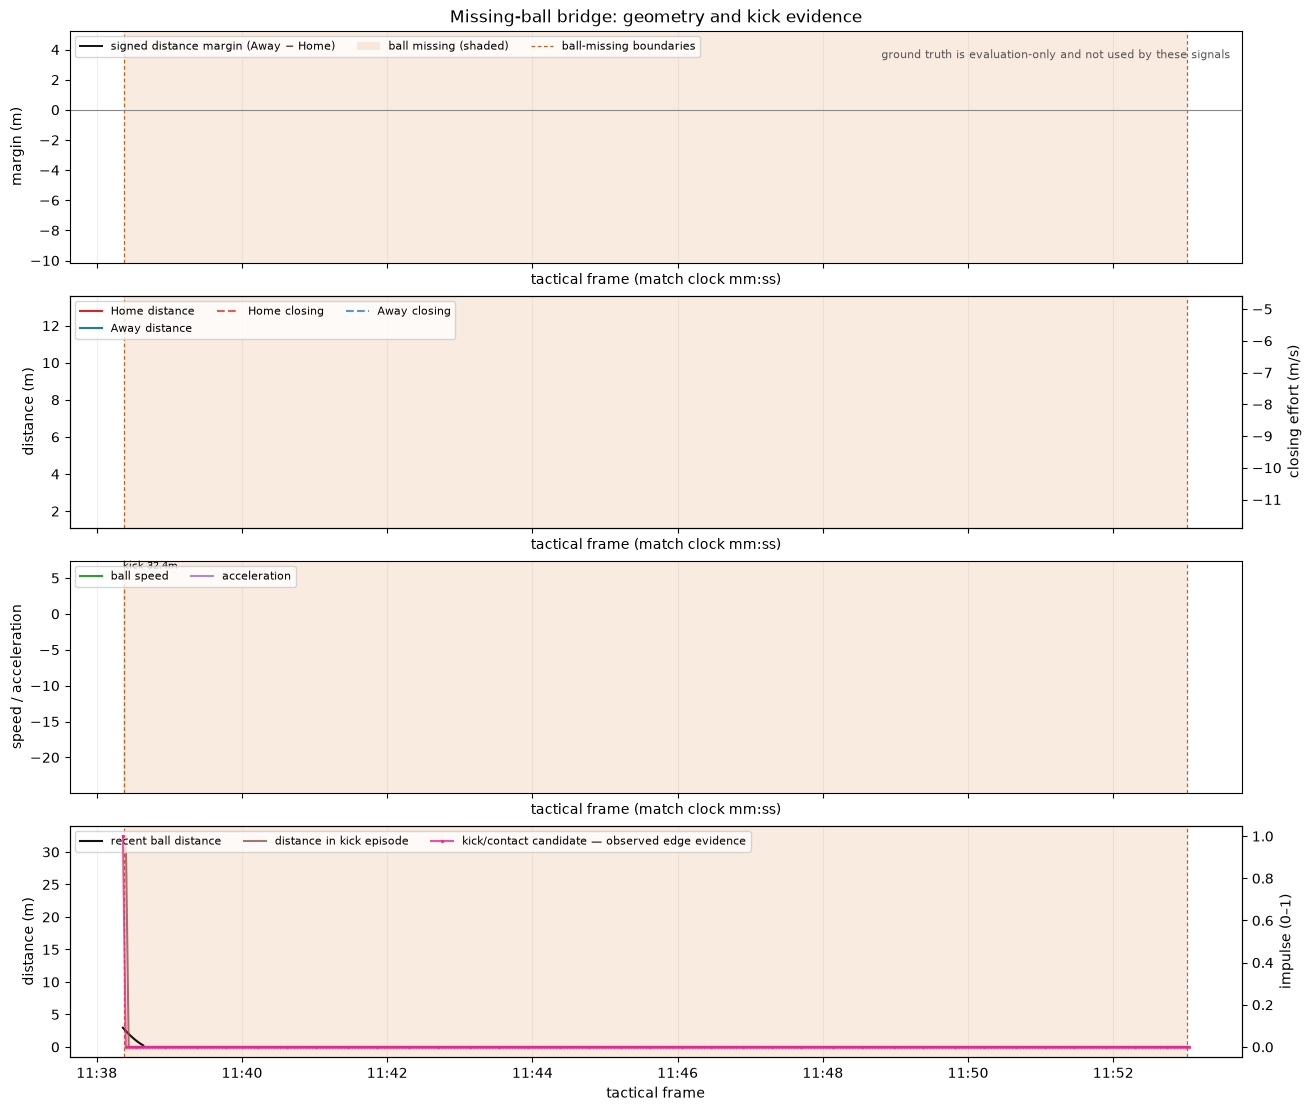

**Full-range playback:** frames 17385–17900; graded H/A/D window; the ball is allowed to disappear honestly.

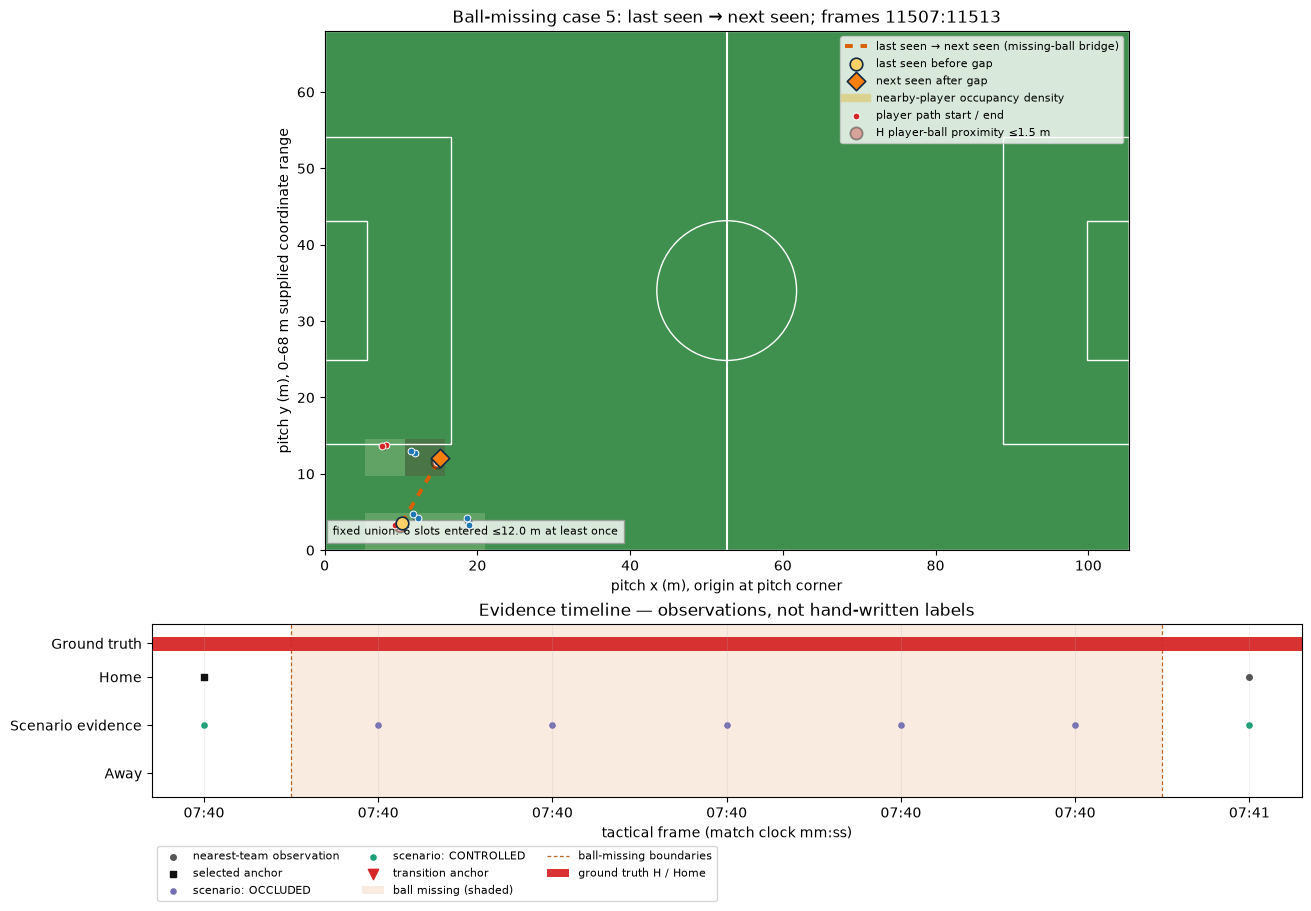

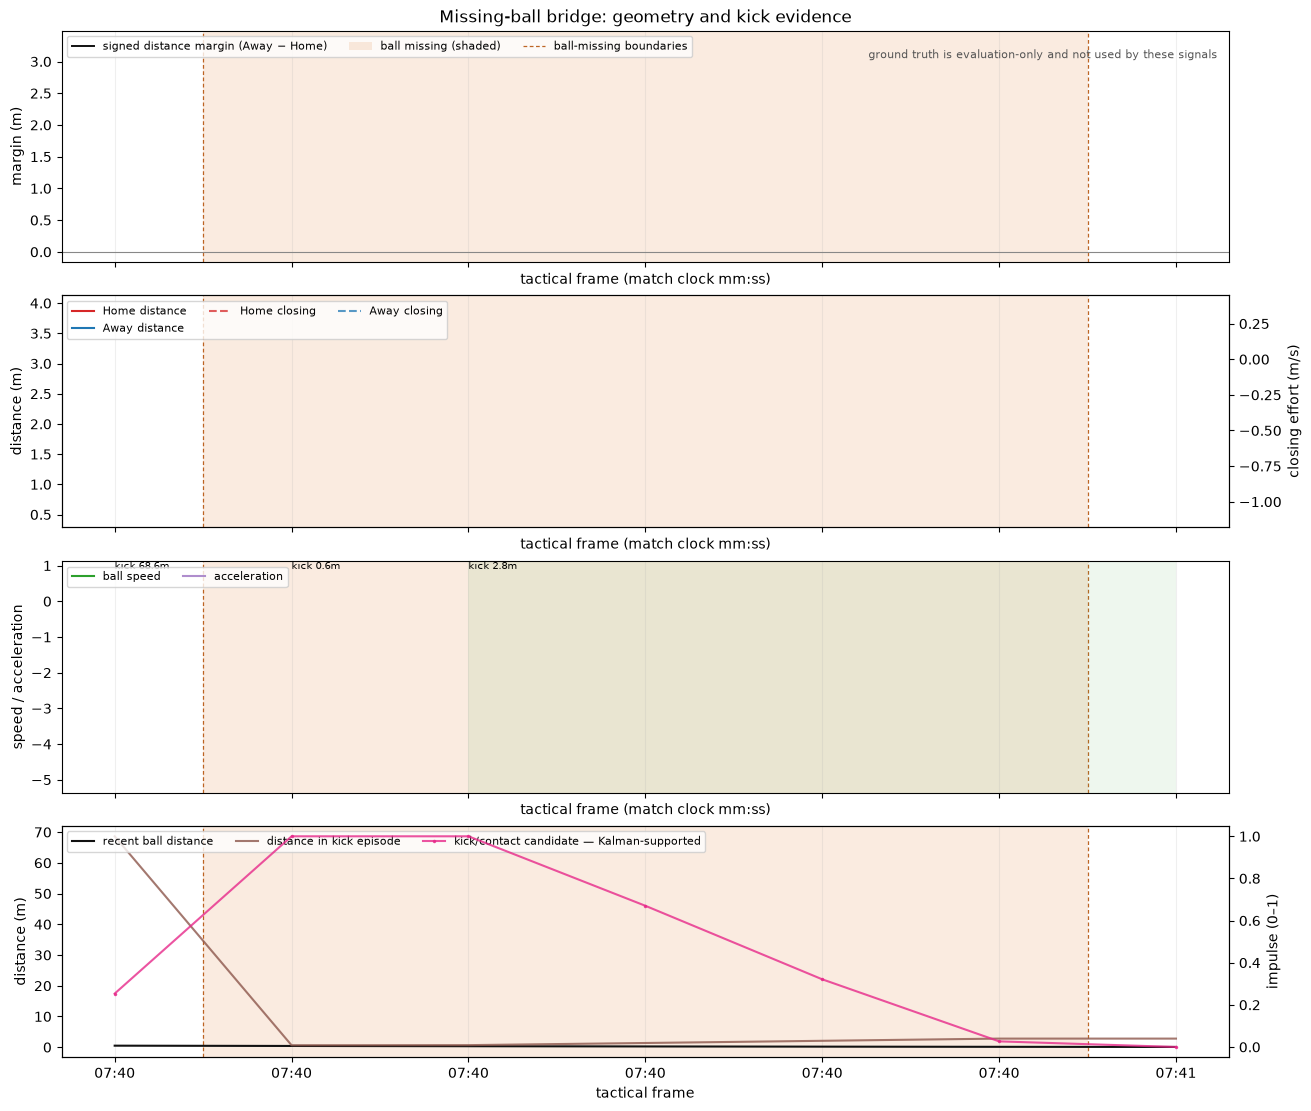

**Full-range playback:** frames 11433–11587; graded H/A/D window; the ball is allowed to disappear honestly.

In [2]:
team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])
try:
    starter_dataset = load_starter_atd(data_dir=str(ROOT / 'data'))
except ImportError as error:
    starter_dataset = None
    print(f'Optional animation loader unavailable: {error}')
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt_by_frame = pd.Series(dtype='string')
if gt_path.exists():
    gt_table = pd.read_csv(gt_path)
    gt_by_frame = gt_table.set_index('frame')['label'].astype(str).str.upper()

graded_cases = []
for row in episodes.itertuples(index=False):
    window = select_ball_gap_event_window(features, (int(row.start_frame), int(row.end_frame)), minimum_context_frames=75)
    window_frames = range(window['start_frame'], window['end_frame'] + 1)
    window_labels = gt_by_frame.reindex(window_frames)
    if window_labels.empty or window_labels.isna().any() or window_labels.eq('X').any():
        continue
    graded_cases.append((row, window))
# Prefer compact, interpretable gaps for the presentation; the public
# grading mask is still the gate, so no `X` frame enters an example.
graded_cases.sort(key=lambda item: (
    0 if 2.0 <= float(item[0].duration_s) <= 20.0 else 1,
    float(item[0].duration_s), int(item[0].start_frame),
))
graded_cases = graded_cases[:6]

for case_number, (row, window) in enumerate(graded_cases, start=1):
    fig, axes = plot_evidence_window(
        features, window['start_frame'], window['end_frame'],
        team_by_slot=team_by_slot, ground_truth=gt_by_frame,
        nearby_radius_m=12.0, nearby_count=6, show_all_reference_players=False, focus_gap=True,
    )
    axes[0].set_title(f'Ball-missing case {case_number}: last seen → next seen; frames {window["last_seen_frame"]}:{window["next_seen_frame"]}')
    plt.show()
    signal_fig, signal_axes = plot_transition_signals_window(
        features, window['last_seen_frame'], window['next_seen_frame'], ground_truth=gt_by_frame
    )
    signal_axes[0].set_title('Missing-ball bridge: geometry and kick evidence')
    plt.show()
    display(Markdown(f'**Full-range playback:** frames {window["start_frame"]}–{window["end_frame"]}; graded H/A/D window; the ball is allowed to disappear honestly.'))
    if starter_dataset is not None:
        display(HTML(animate_frames(starter_dataset, int(window['start_frame']), int(window['end_frame']) + 1).to_html5_video()))
    else:
        display(Markdown('Animation skipped: install `requirements-starter.txt` to enable optional video playback. The evidence plot remains runnable from the canonical feature table.'))

if not graded_cases:
    display(Markdown('No fully graded H/A/D missing-ball windows were found; ungraded `X` examples were intentionally excluded.'))

# Missing-ball evidence boundary

### Problem

A missing ball coordinate is not necessarily a change of possession. It may be an occlusion, an aerial pass, an out-of-play episode, or a missing-player episode. The main pipeline treats the gap as an interval with uncertainty rather than filling it with a smooth curve and assigning a team.

### Idea

Use source-aware, two-sided evidence: compare the last and next reliable ball observations, test straight and deflection paths, estimate uncertainty, and ask whether a plausible receiver arrives and controls the landing. Player motion can support or reject a path, but no reconstructed coordinate should directly create `H` or `A`.

The dedicated alternate-camera study is kept in [Appendix — alternate ball observations](appendix/04c_alternate_ball_observations.ipynb). It explains provenance, flight reconstruction, model-imputed coordinates, uncertainty, and safe downstream use. This notebook focuses on the football question the main pipeline must solve when the ball or likely carrier disappears.